# Análisis exploratorio de datos (EDA) — corpus y batería de evaluación

**Tesis:** *Desarrollo y evaluación de un chatbot educativo basado en IA generativa y RAG para reforzar el aprendizaje de cinemática preuniversitaria en una academia de Chachapoyas* — Elmer Dante Rojas Zuta (MIA-UNI).

En esta etapa los datos del proyecto son dos:

| Conjunto | Qué es | Para qué sirve |
|---|---|---|
| **Corpus v5.1** | 136 fichas de teoría, procedimientos y ejemplos resueltos de cinemática | Es lo que el chatbot **consulta** (la parte *R* de RAG) |
| **Batería v4** | 400 preguntas con clave, solución de referencia y fichas esperadas | Es el **examen** con el que se evalúa al chatbot |

Todavía no hay datos de estudiantes: llegarán en el estudio educativo. Este EDA verifica que el material con el que **se construye** el sistema y el material con el que **se le evalúa** sean adecuados antes de la experimentación.

**Preguntas que responde el análisis**
1. ¿El corpus cubre los cinco subtemas de forma equilibrada y con fichas de tamaño adecuado para la recuperación?
2. ¿La batería está balanceada por subtema, componente, nivel, partición y posición de la clave?
3. ¿De dónde proviene cada pregunta y cómo se verificó?
4. ¿El corpus contiene la información que pide cada pregunta? ¿Hay fichas sin uso o temas sin cobertura?
5. ¿Hay filtración entre la batería y el corpus?

> **Reproducibilidad.** El notebook usa solo archivos publicados en `data/`. Las preguntas tomadas de libros con derechos de autor se publican con su referencia exacta y sus métricas (longitud, nivel, clave), pero sin el enunciado; por eso todos los resultados se reproducen desde un clon limpio del repositorio.

In [1]:
import sys, json, collections
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src") if Path.cwd().name == "notebooks" else "src")
import pandas as pd, numpy as np, matplotlib.pyplot as plt
import eda_utils as u
u.estilo()
pd.set_option("display.max_colwidth", 80)
corpus = u.cargar_corpus()
bat = u.cargar_bateria()
inv = u.cargar_inventario()
print(f"Corpus: {len(corpus)} fichas · Batería: {len(bat)} preguntas · Fuentes revisadas: {len(inv)}")

Corpus: 136 fichas · Batería: 400 preguntas · Fuentes revisadas: 6


## 1. Corpus

### 1.1 Composición por subtema y tipo de ficha

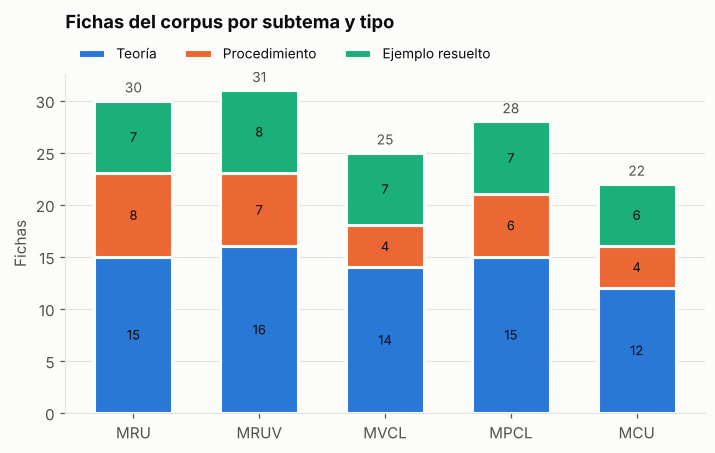

,Teoría,Procedimiento,Ejemplo resuelto,Total
subtema,,,,
MRU,15,8,7,30
MRUV,16,7,8,31
MVCL,14,4,7,25
MPCL,15,6,7,28
MCU,12,4,6,22


In [2]:
tab = corpus.groupby(["subtema", "tipo"]).size().unstack(fill_value=0).reindex(u.SUBTEMAS)[["teoria", "procedimiento", "ejemplo"]]
tab.columns = ["Teoría", "Procedimiento", "Ejemplo resuelto"]
u.guardar_tabla(tab, "corpus_subtema_tipo")
fig, ax = plt.subplots(figsize=(7.5, 4))
u.barras_apiladas(ax, tab, u.SERIE[:3])
ax.set_title("Fichas del corpus por subtema y tipo", pad=30); ax.set_ylabel("Fichas"); ax.grid(axis="x", visible=False)
ax.legend(ncol=3, loc="lower left", bbox_to_anchor=(0, 1.0), fontsize=9)
u.guardar(fig, "01_corpus_subtema_tipo"); plt.show()
display(tab.assign(Total=tab.sum(axis=1)))

**Lectura.** Los cinco subtemas tienen entre 22 y 31 fichas. MCU y MVCL son los más pequeños, lo que es coherente con su menor extensión en el temario. En todos los subtemas predominan las fichas de teoría (≈ 53 %), seguidas de procedimientos (≈ 21 %) y ejemplos resueltos (≈ 26 %).

### 1.2 Longitud de las fichas (palabras y tokens estimados)

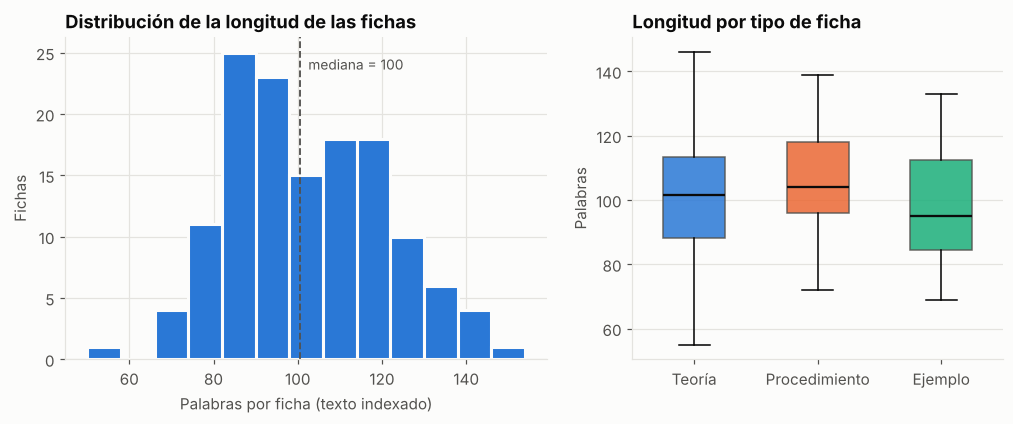

Total del corpus ≈ 13,842 palabras ≈ 22,147 tokens (estimado).


palabras                     tokens_est                     
                  mean   min    50%    max       mean    min    50%    max
tipo                                                                      
ejemplo           98.7  69.0   95.0  133.0      157.9  110.0  152.0  213.0
procedimiento    106.3  72.0  104.0  139.0      170.1  115.0  166.0  222.0
teoria           101.4  55.0  101.5  146.0      162.3   88.0  162.5  234.0

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw=dict(width_ratios=[1.3, 1]))
axs[0].hist(corpus["palabras"], bins=range(50, 160, 8), color=u.SERIE[0], edgecolor=u.SUPERFICIE, linewidth=2)
axs[0].axvline(corpus["palabras"].median(), color=u.TINTA_2, linestyle="--", linewidth=1.2)
axs[0].text(corpus["palabras"].median() + 2, axs[0].get_ylim()[1] * 0.9, f"mediana = {corpus['palabras'].median():.0f}", color=u.TINTA_2, fontsize=9)
axs[0].set_title("Distribución de la longitud de las fichas"); axs[0].set_xlabel("Palabras por ficha (texto indexado)"); axs[0].set_ylabel("Fichas")
orden = ["teoria", "procedimiento", "ejemplo"]
datos = [corpus.loc[corpus.tipo == t, "palabras"] for t in orden]
bp = axs[1].boxplot(datos, tick_labels=["Teoría", "Procedimiento", "Ejemplo"], patch_artist=True, widths=0.5,
                    medianprops=dict(color=u.TINTA, linewidth=1.5))
for p, c in zip(bp["boxes"], u.SERIE[:3]): p.set_facecolor(c); p.set_alpha(0.85); p.set_edgecolor(u.TINTA_2)
axs[1].set_title("Longitud por tipo de ficha"); axs[1].set_ylabel("Palabras"); axs[1].grid(axis="x", visible=False)
u.guardar(fig, "02_corpus_longitud"); plt.show()
resumen = corpus.groupby("tipo")[["palabras", "tokens_est"]].describe().loc[:, (slice(None), ["mean", "min", "50%", "max"])].round(1)
u.guardar_tabla(resumen, "corpus_longitud")
print(f"Total del corpus ≈ {corpus.palabras.sum():,} palabras ≈ {corpus.tokens_est.sum():,} tokens (estimado).")
resumen

**Lectura.** Las fichas tienen entre 55 y 146 palabras (mediana ≈ 100), es decir, unos 90–235 tokens. Esto confirma que cada ficha es una **unidad semántica completa y homogénea**, adecuada para usarse directamente como fragmento (*chunk*) del RAG, sin volver a partirla.

Con k = 5 fichas recuperadas, el contexto ocuparía ≈ 800–1200 tokens, una fracción pequeña de la ventana de cualquier LLM actual. El corpus completo cabe en ≈ 22 000 tokens.

*Nota:* los tokens se estiman con un factor de 1,6 tokens por palabra en español; el valor exacto depende del tokenizador del modelo elegido.

### 1.3 Contenido estructurado y fuentes

In [4]:
cont = corpus.groupby("tipo").agg(fichas=("id", "count"), con_ecuaciones=("n_ecuaciones", lambda s: (s > 0).sum()),
                                   con_error_frecuente=("n_errores", lambda s: (s > 0).sum()))
fuentes = corpus["fuente_libro"].value_counts().rename("fichas")
u.guardar_tabla(cont, "corpus_contenido"); u.guardar_tabla(fuentes.to_frame(), "corpus_fuentes")
display(cont); display(fuentes.to_frame())

,fichas,con_ecuaciones,con_error_frecuente
tipo,,,
ejemplo,35,0,6
procedimiento,29,24,20
teoria,72,58,41


,fichas
fuente_libro,
Lumbreras,72
"Giancoli, Lumbreras",50
Giancoli,11
Síntesis propia,3


**Lectura.** Las fichas de teoría y procedimiento traen, además del texto, sus relaciones (ecuaciones) y los errores frecuentes del alumno. Estos campos sirven para que el chatbot advierta las equivocaciones típicas.

Todas las fichas citan su fuente: el texto es una síntesis propia basada en *Física esencial* (Lumbreras) y *Física* de Giancoli, y no reproduce texto de los libros. Las 3 fichas de «síntesis propia» se agregaron en la v5.1 para cubrir vacíos detectados en el material de la academia: un cuerpo soltado desde un móvil, la caída libre en otro astro y el movimiento sobre un medio que se mueve.

## 2. Batería de evaluación

### 2.1 Composición por diseño

In [5]:
comp = bat.assign(grupo=np.where(bat.componente == "practica", "práctica · " + bat.nivel, bat.componente))
tab = comp.groupby(["subtema", "grupo"]).size().unstack(fill_value=0).reindex(u.SUBTEMAS)
tab = tab[["teoria", "práctica · basico", "práctica · intermedio", "práctica · avanzado", "no_respondible"]]
tab.columns = ["Teoría", "Práctica básica", "Práctica intermedia", "Práctica avanzada", "No respondible"]
tab.loc["Total"] = tab.sum(); tab["Total"] = tab.sum(axis=1)
u.guardar_tabla(tab, "bateria_composicion"); tab

,Teoría,Práctica básica,Práctica intermedia,Práctica avanzada,No respondible,Total
subtema,,,,,,
MRU,18,18,18,18,8,80
MRUV,18,18,18,18,8,80
MVCL,18,18,18,18,8,80
MPCL,18,18,18,18,8,80
MCU,18,18,18,18,8,80
Total,90,90,90,90,40,400


**Lectura.** La batería cumple exactamente el diseño del proyecto: 80 preguntas por subtema; en cada uno, 18 de teoría, 18 de práctica por nivel (básico, intermedio y avanzado) y 8 que el chatbot **no** debería responder. Estas últimas son preguntas fuera de dominio, con datos incompletos o ambiguas, y sirven para medir la abstención. Este equilibrio es lo que permite comparar el desempeño entre subtemas y niveles sin que uno pese más que otro.

### 2.2 Origen de las preguntas

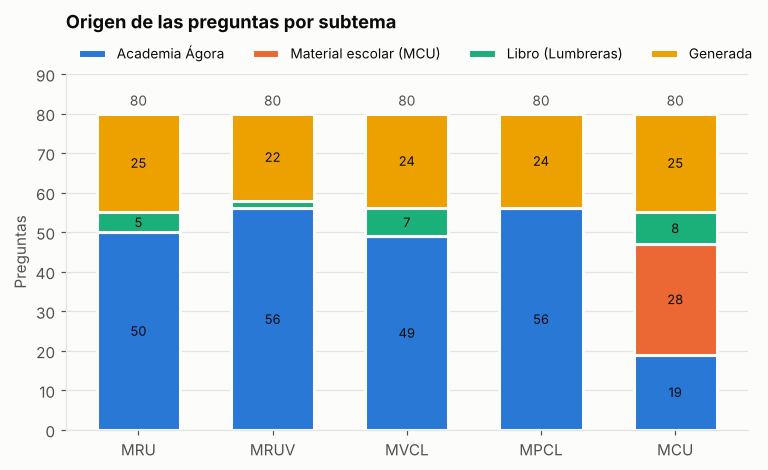

origen,Academia Ágora,Material escolar (MCU),Libro (Lumbreras),Generada
componente,,,,
no_respondible,1,0,0,39
practica,223,28,19,0
teoria,6,0,3,81


Preguntas originales (no generadas): 280 de 400 (70%)


In [6]:
ORIG = {"Ágora": "Academia Ágora", "escolar": "Material escolar (MCU)", "libro": "Libro (Lumbreras)", "generada": "Generada"}
tab = bat.groupby(["subtema", "origen"]).size().unstack(fill_value=0).reindex(u.SUBTEMAS)[list(ORIG)].rename(columns=ORIG)
u.guardar_tabla(tab, "bateria_origen_subtema")
fig, ax = plt.subplots(figsize=(8, 4.2))
u.barras_apiladas(ax, tab, u.SERIE[:4])
ax.set_title("Origen de las preguntas por subtema", pad=30); ax.set_ylabel("Preguntas"); ax.grid(axis="x", visible=False)
ax.set_ylim(0, 90); ax.legend(ncol=4, loc="lower left", bbox_to_anchor=(0, 1.0), fontsize=9)
u.guardar(fig, "03_bateria_origen"); plt.show()
orig_comp = pd.crosstab(bat.componente, bat.origen).reindex(columns=list(ORIG)).rename(columns=ORIG)
display(orig_comp)
print(f"Preguntas originales (no generadas): {(bat.origen != 'generada').sum()} de {len(bat)} ({(bat.origen != 'generada').mean():.0%})")

**Lectura.** El 70 % de la batería (280 preguntas) es **material real**: 230 preguntas de la academia Ágora, 28 de material escolar de MCU adaptado y 22 de Lumbreras. Toda la **práctica** es original: no queda ninguna pregunta de práctica generada.

Las 120 preguntas generadas son, por diseño:
- 39 **no respondibles**, que tienen que inventarse (una de las 40 es real: una pregunta de MCUV del material de Ágora);
- 81 de **teoría**, porque el material de la academia casi no trae preguntas conceptuales.

Esta es la principal limitación de la batería y se declara en la tesis. Esas preguntas están pendientes de revisión docente.

### 2.3 Balance de la partición desarrollo / validación / evaluación final

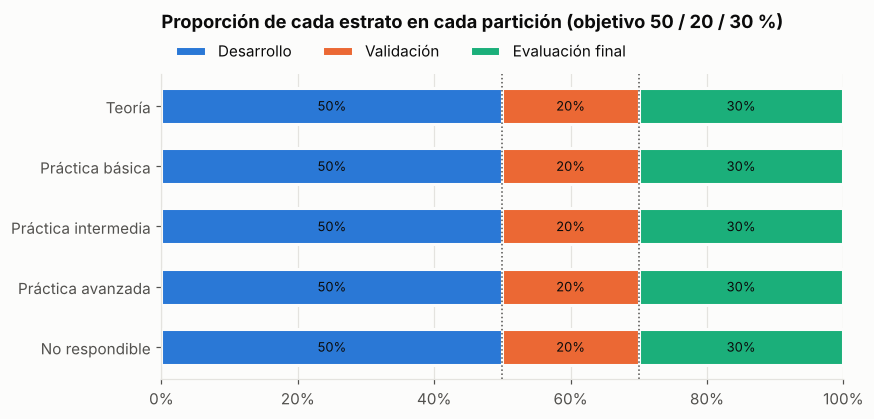

Familias con más de una pregunta: 5 · familias partidas entre conjuntos: 0


particion,desarrollo,validacion,evaluacion_final
subtema,,,
MRU,40,16,24
MRUV,40,16,24
MVCL,40,16,24
MPCL,40,16,24
MCU,40,16,24
Total,200,80,120


In [7]:
tab = pd.crosstab(bat.subtema, bat.particion).reindex(index=u.SUBTEMAS, columns=u.PARTICIONES)
tab.loc["Total"] = tab.sum()
estrato = np.where(bat.componente == "practica", "practica · " + bat.nivel, bat.componente)
prop = pd.crosstab(estrato, bat.particion, normalize="index").reindex(columns=u.PARTICIONES).round(3)
u.guardar_tabla(tab, "particion_subtema"); u.guardar_tabla(prop, "particion_estratos")
fig, ax = plt.subplots(figsize=(8, 3.6))
ETQ = {"teoria": "Teoría", "practica · basico": "Práctica básica", "practica · intermedio": "Práctica intermedia",
       "practica · avanzado": "Práctica avanzada", "no_respondible": "No respondible"}
estr = prop.reindex(list(ETQ)); estr.index = list(ETQ.values())
izq = np.zeros(len(estr))
for col, color, nombre in zip(u.PARTICIONES, u.SERIE[:3], ["Desarrollo", "Validación", "Evaluación final"]):
    ax.barh(estr.index, estr[col], left=izq, color=color, edgecolor=u.SUPERFICIE, linewidth=2, label=nombre, height=0.6)
    for y, (v, l) in enumerate(zip(estr[col], izq)): ax.text(l + v / 2, y, f"{v:.0%}", ha="center", va="center", fontsize=8.5)
    izq += estr[col].values
for x in (0.5, 0.7): ax.axvline(x, color=u.TINTA_2, linestyle=":", linewidth=1)
ax.set_xlim(0, 1); ax.set_title("Proporción de cada estrato en cada partición (objetivo 50 / 20 / 30 %)", pad=30)
ax.invert_yaxis(); ax.legend(ncol=3, loc="lower left", bbox_to_anchor=(0, 1.0)); ax.grid(axis="y", visible=False); ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
u.guardar(fig, "04_particion_estratos"); plt.show()
fam = bat.groupby("familia").particion.nunique()
print(f"Familias con más de una pregunta: {(bat.familia.value_counts() > 1).sum()} · familias partidas entre conjuntos: {(fam > 1).sum()}")
tab

**Lectura.** La partición es **exacta en todos los cortes**:
- cada subtema aporta 40/16/24 preguntas;
- cada estrato (teoría, práctica básica, intermedia y avanzada, no respondible) se reparte exactamente 50/20/30 %.

El EDA detectó que, tras la primera asignación, la validación tenía solo 6 de las 40 preguntas no respondibles. Ese es justamente el conjunto que se usa para calibrar el umbral de abstención τ. Se corrigió con 4 intercambios dentro del mismo subtema. La partición es reproducible porque se genera con una semilla fija.

Las preguntas de una misma **familia**, es decir, la misma situación con otros datos, siempre caen en el mismo conjunto; ninguna familia queda partida. Así se evita que el sistema se ajuste en desarrollo con una pregunta y luego se evalúe con su «gemela».

### 2.4 Posición de la clave y valor de g

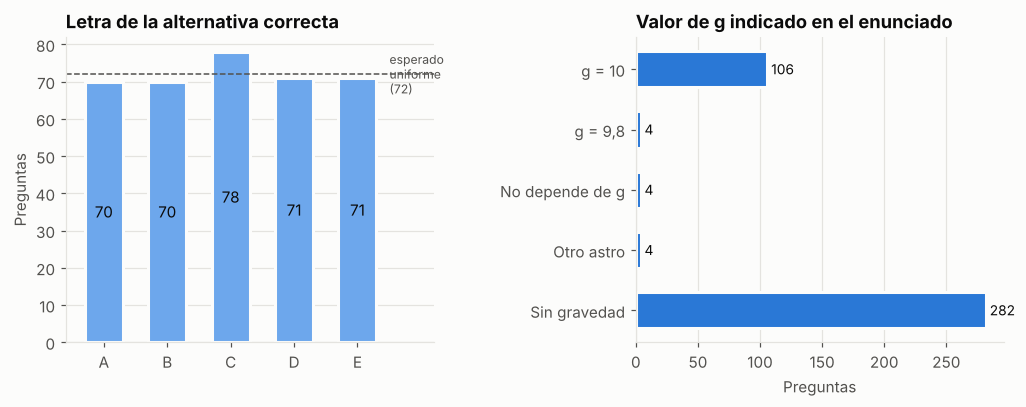

χ² de uniformidad de la clave: p = 0.96


In [8]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
letras = bat.loc[bat.clave.notna() & (bat.clave != ""), "clave"].value_counts().reindex(list("ABCDE"))
axs[0].bar(letras.index, letras.values, color=u.SECUENCIAL[2], edgecolor=u.SUPERFICIE, linewidth=2, width=0.6)
esperado = letras.sum() / 5
axs[0].axhline(esperado, color=u.TINTA_2, linestyle="--", linewidth=1)
axs[0].text(4.45, esperado, f" esperado\n uniforme\n ({esperado:.0f})", color=u.TINTA_2, fontsize=8, va="center", ha="left")
for x, v in enumerate(letras.values): axs[0].text(x, v / 2, str(v), ha="center", va="center", fontsize=10, color=u.TINTA)
axs[0].set_xlim(-0.6, 5.2)
axs[0].set_title("Letra de la alternativa correcta"); axs[0].set_ylabel("Preguntas"); axs[0].grid(axis="x", visible=False)
G = {"10": "g = 10", "9.8": "g = 9,8", "no_requerido": "No depende de g", "otro_astro": "Otro astro", "no_aplica": "Sin gravedad"}
gv = bat.g.astype(str).map(G).value_counts().reindex(list(G.values())).fillna(0)
axs[1].barh(gv.index[::-1], gv.values[::-1], color=u.SERIE[0], edgecolor=u.SUPERFICIE, linewidth=2, height=0.6)
for y, v in enumerate(gv.values[::-1]): axs[1].text(v + 3, y, str(int(v)), va="center", fontsize=9)
axs[1].set_title("Valor de g indicado en el enunciado"); axs[1].set_xlabel("Preguntas"); axs[1].grid(axis="y", visible=False)
fig.subplots_adjust(wspace=0.55); u.guardar(fig, "05_clave_y_g"); plt.show()
from scipy.stats import chisquare
print(f"χ² de uniformidad de la clave: p = {chisquare(letras.values).pvalue:.2f}")

**Lectura.**
- **Posición de la clave:** la alternativa correcta se reparte casi por igual entre A y E (70–78 preguntas por letra; la prueba χ² no detecta desbalance). Así, un modelo que tiende a elegir una misma letra no obtiene ventaja. Solo se reordenaron las alternativas de las preguntas generadas; las de Ágora y de los libros conservan su orden original.
- **Valor de g:** **toda pregunta cuya respuesta depende de g indica su valor.** 106 usan g = 10 m/s² y 4 usan g = 9,8 m/s², por lo que el chatbot debe respetar el dato del enunciado. Otras 4 piden calcular la gravedad de otro astro y 4 no dependen de g, como tan θ = 4H/D.

### 2.5 Longitud de los enunciados y trazabilidad

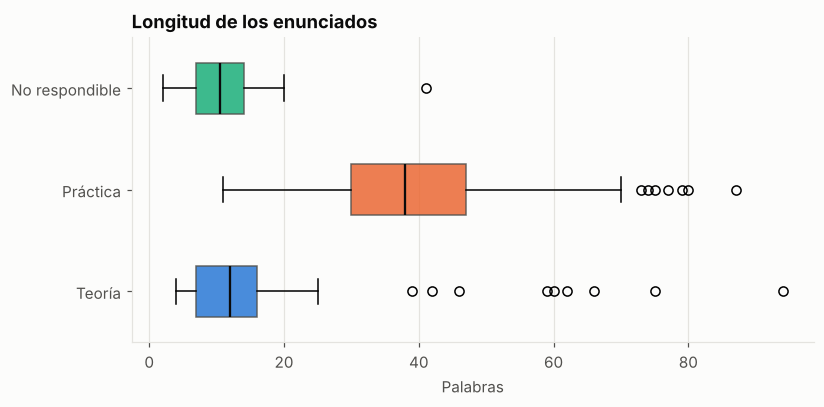

,preguntas
verificacion,
clave confirmada por el docente (14-10-2026),258
pendiente de revisión docente,120
clave cotejada con el libro físico por el docente (14-10-2026),14
clave impresa en el libro (legible en el escaneo),8
Preguntas modificadas (con motivo registrado),121


In [9]:
fig, ax = plt.subplots(figsize=(8, 3.6))
orden = [c for c in ["teoria", "practica", "no_respondible"]]
datos = [bat.loc[bat.componente == c, "n_palabras_enunciado"] for c in orden]
bp = ax.boxplot(datos, tick_labels=["Teoría", "Práctica", "No respondible"], orientation="horizontal", patch_artist=True, widths=0.5, medianprops=dict(color=u.TINTA, linewidth=1.5))
for p, c in zip(bp["boxes"], u.SERIE[:3]): p.set_facecolor(c); p.set_alpha(0.85); p.set_edgecolor(u.TINTA_2)
ax.set_title("Longitud de los enunciados"); ax.set_xlabel("Palabras"); ax.grid(axis="y", visible=False)
u.guardar(fig, "06_bateria_longitud"); plt.show()
traz = pd.DataFrame({"preguntas": bat.groupby("verificacion").size()}).sort_values("preguntas", ascending=False)
traz.loc["Preguntas modificadas (con motivo registrado)"] = int(bat.modificada.sum())
u.guardar_tabla(traz, "bateria_verificacion"); traz

**Lectura.** Las preguntas de práctica son las más largas (mediana de 38 palabras, frente a unas 11–12 en teoría y en las no respondibles), porque incluyen datos y, cuando el original traía una figura, su descripción en texto: el chatbot recibe solo texto. Las de teoría y las no respondibles son cortas, como los mensajes reales de WhatsApp.

**Trazabilidad:**
- Las 280 preguntas originales tienen su **clave verificada**: confirmada por el docente, impresa en el libro o cotejada con el libro físico.
- Las 120 generadas están marcadas como pendientes de revisión.
- Cada pregunta cambiada respecto de su fuente (figura descrita, dato agregado, alternativa corregida) tiene su motivo registrado en `data/bateria/registro_verificacion.csv`.

## 3. Relación entre la batería y el corpus

### 3.1 ¿Qué fichas necesita cada pregunta?

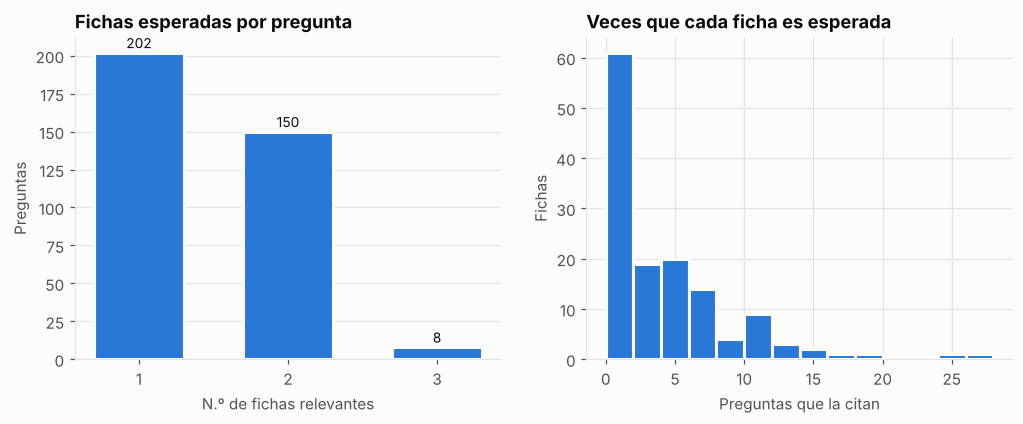

Preguntas respondibles: 360 · fichas citadas: 89 de 136 · fichas sin uso: 47 · ids inexistentes: []


,mean,median,max
tipo,,,
ejemplo,0.0,0.0,0
procedimiento,3.1,2.0,12
teoria,6.1,5.0,27


,id,titulo,usos
69,CIN-MVCL-T009,Ecuaciones escalares del MVCL,27
35,CIN-MRUV-T006,Ecuaciones del MRUV,25
119,CIN-MCU-T006,Periodo y frecuencia,18
8,CIN-MRU-T009,Ecuación del MRU,17
118,CIN-MCU-T005,Rapidez tangencial y su relación con la rapidez angular,15
122,CIN-MCU-T009,Puntos de un mismo disco o poleas concéntricas,14
90,CIN-MPCL-T005,Lanzamiento horizontal,13
70,CIN-MVCL-T010,Ecuaciones vectoriales del MVCL,12


In [10]:
resp = bat[bat.respondible]
uso = collections.Counter(u_ for us in resp.unidades for u_ in us)
corpus["usos"] = corpus["id"].map(uso).fillna(0).astype(int)
sin_uso = corpus.loc[corpus.usos == 0, ["id", "titulo", "tipo"]]
inexistentes = sorted({x for us in resp.unidades for x in us} - set(corpus.id))
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
nu = resp.n_unidades.value_counts().sort_index()
axs[0].bar(nu.index.astype(str), nu.values, color=u.SERIE[0], edgecolor=u.SUPERFICIE, linewidth=2, width=0.6)
for x, v in enumerate(nu.values): axs[0].text(x, v + 3, str(v), ha="center", fontsize=9)
axs[0].set_title("Fichas esperadas por pregunta"); axs[0].set_xlabel("N.º de fichas relevantes"); axs[0].set_ylabel("Preguntas"); axs[0].grid(axis="x", visible=False)
por_tipo = corpus.groupby("tipo").usos.agg(["mean", "median", "max"]).round(1)
axs[1].hist(corpus.usos, bins=range(0, corpus.usos.max() + 3, 2), color=u.SERIE[0], edgecolor=u.SUPERFICIE, linewidth=2)
axs[1].set_title("Veces que cada ficha es esperada"); axs[1].set_xlabel("Preguntas que la citan"); axs[1].set_ylabel("Fichas")
u.guardar(fig, "07_cobertura"); plt.show()
print(f"Preguntas respondibles: {len(resp)} · fichas citadas: {len(uso)} de {len(corpus)} · fichas sin uso: {len(sin_uso)} · ids inexistentes: {inexistentes}")
u.guardar_tabla(corpus.sort_values("usos", ascending=False)[["id", "titulo", "usos"]].set_index("id"), "uso_fichas")
display(por_tipo)
display(corpus.sort_values("usos", ascending=False)[["id", "titulo", "usos"]].head(8))

**Lectura.**
- **Anotación:** cada una de las 360 preguntas respondibles tiene anotadas entre 1 y 3 fichas que el buscador debería recuperar (202 con una, 150 con dos y 8 con tres). Es el **estándar de oro** con el que se calcularán Recall@k y MRR en la evaluación técnica.
- **Referencias válidas:** las preguntas citan 89 de las 136 fichas y no hay referencias a fichas inexistentes.
- **Fichas más citadas:** son las ecuaciones de cada movimiento, como era de esperar.
- **Fichas sin uso (47):** 35 son los ejemplos resueltos, porque ninguna pregunta se anotó contra un ejemplo (las preguntas piden aplicar teoría y procedimientos, no copiar un ejemplo). No sobran: aportan contexto al RAG, pero su aporte se medirá indirectamente, por la calidad de la respuesta, y no por Recall@k. Las otras 12 son 10 procedimientos y 2 fichas de teoría que ninguna pregunta exige directamente; se revisarán al anotar el corpus v6.

In [11]:
display(sin_uso.groupby("tipo").size().rename("fichas sin uso").to_frame())
parc = bat[bat.cobertura_parcial]
print(f"Preguntas con cobertura parcial del corpus: {len(parc)}")
display(parc.groupby("subtema").size().rename("preguntas").to_frame())

,fichas sin uso
tipo,
ejemplo,35
procedimiento,10
teoria,2


Preguntas con cobertura parcial del corpus: 11


,preguntas
subtema,
MRU,6
MRUV,4
MVCL,1


**Lectura.** **Hay 11 preguntas con cobertura parcial** (6 de MRU, 4 de MRUV y 1 de MVCL): los conocimientos que piden no tienen todavía una ficha específica en el corpus. Son:
- sombras proyectadas (semejanza de triángulos);
- cinemática vectorial (posición y velocidad como vectores);
- ecuaciones de posición x(t);
- rumbos y cruce de un río (velocidad relativa en 2D).

Este es un hallazgo accionable del EDA: define las **4–5 fichas nuevas del corpus v6**. Mientras tanto, esas preguntas se pueden analizar por separado en la evaluación, porque son las que más probablemente fallen por falta de contexto y no por el modelo.

### 3.2 Control de filtración entre la batería y el corpus

In [12]:
sim = bat.n_similares_corpus
print(f"Preguntas con estructura parecida a algún ejemplo del corpus (Jaccard léxico > 0,45): {(sim > 0).sum()} de {len(bat)}")
display(bat.loc[sim > 0].groupby(["subtema", "origen"]).size().rename("preguntas").to_frame())

Preguntas con estructura parecida a algún ejemplo del corpus (Jaccard léxico > 0,45): 17 de 400


preguntas
subtema origen             
MCU     escolar           1
MPCL    Ágora             6
MRUV    generada          1
        Ágora             3
MVCL    libro             1
        Ágora             5

**Lectura.**
- **Ninguna pregunta está copiada en el corpus.** Las 17 que superan el umbral comparten la estructura con algún ejemplo resuelto («lanzamiento horizontal desde una mesa», «poleas unidas por faja»), pero tienen otros datos.
- **Se mantienen a propósito:** el objetivo del RAG es justamente que el chatbot use un procedimiento afín para resolver un problema nuevo.
- **Uso en la evaluación:** el indicador queda en los metadatos para comparar si el chatbot acierta más en las preguntas parecidas al corpus que en las demás.

## 4. Origen y selección: de 890 preguntas revisadas a 400

,revisadas,verificadas,no_verificadas,en_bateria_v4,nota
etiqueta,,,,,
Lumbreras,271,256,15,22,"No verificadas (15): 8 de MCUV (fuera de alcance), 4 con figura ambigua y 3 ..."
Ágora: MATERIAL ÁGORA,119,118,1,116,No verificada (1): repetida dentro del mismo material. Claves de las 118 res...
Ágora: histórico,339,266,73,114,"Verificadas (266): claves confirmadas por el docente: FÍSICA Temas 1–4 (54),..."
Escolar (MCU),81,54,27,28,"No verificadas (27): repetidas, sin datos, eliminadas por el docente o ejerc..."
Aula20,80,0,80,0,No se usa en Ágora; no se verificó. Queda como reserva para pruebas de desar...
Generadas,170,0,170,120,"Teoría (87), no respondibles (40) y práctica de respaldo (43). No tienen fue..."


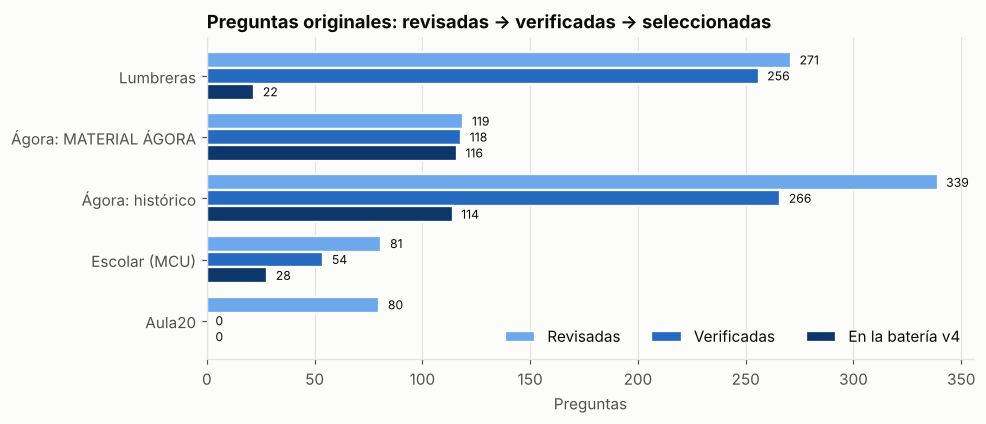

Originales: 890 revisadas = 694 verificadas + 196 no verificadas · 280 seleccionadas para la batería


In [13]:
inv2 = inv.copy()
inv2["etiqueta"] = ["Lumbreras", "Ágora: MATERIAL ÁGORA", "Ágora: histórico", "Escolar (MCU)", "Aula20", "Generadas"]
display(inv2[["etiqueta", "revisadas", "verificadas", "no_verificadas", "en_bateria_v4", "nota"]].set_index("etiqueta"))
orig = inv2[inv2.origen != "generada"]
fig, ax = plt.subplots(figsize=(9, 3.8))
y = np.arange(len(orig))
for k, (col, color, nombre) in enumerate(zip(["revisadas", "verificadas", "en_bateria_v4"], u.SECUENCIAL[2::2][:3], ["Revisadas", "Verificadas", "En la batería v4"])):
    ax.barh(y + (k - 1) * 0.26, orig[col], height=0.26, color=color, edgecolor=u.SUPERFICIE, linewidth=1.5, label=nombre)
    for yy, v in zip(y + (k - 1) * 0.26, orig[col]): ax.text(v + 4, yy, str(int(v)), va="center", fontsize=8)
ax.set_yticks(y, orig["etiqueta"]); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_title("Preguntas originales: revisadas → verificadas → seleccionadas"); ax.set_xlabel("Preguntas")
ax.legend(ncol=3, loc="lower right")
u.guardar(fig, "08_embudo_fuentes"); plt.show()
tot = orig[["revisadas", "verificadas", "no_verificadas", "en_bateria_v4"]].sum()
assert (orig.revisadas == orig.verificadas + orig.no_verificadas).all()  # el embudo cuadra fila por fila
print(f"Originales: {tot.revisadas} revisadas = {tot.verificadas} verificadas + {tot.no_verificadas} no verificadas · {tot.en_bateria_v4} seleccionadas para la batería")

**Lectura.** Se revisaron 890 preguntas originales, y cada fila del inventario cumple *revisadas = verificadas + no verificadas*:
- **Verificadas (694):** con su clave confirmada por el docente, impresa en el libro o cotejada con el libro físico.
- **No verificadas (196):** no pasaron a la verificación: repetidas entre materiales, defectuosas (sin alternativa correcta, sin datos o con datos contradictorios), fuera de alcance (MCUV) o de una academia externa que Ágora no usa.
- **Seleccionadas (280):** de las verificadas, estratificadas por subtema, componente y nivel, con prioridad para el material de Ágora.
- **Verificadas no seleccionadas (414):** la mayoría queda como **reserva** para escribir ejemplos resueltos del corpus v6, sin repetir ninguna variante de la batería, y para pruebas de desarrollo. Algunas del material histórico se retiraron después de verificarlas (repetidas con otros materiales, anuladas u omitidas por el docente); cada caso está en `registro_verificacion.csv` o en la nota del inventario.

En suma, la batería **no se generó sintéticamente**: se seleccionó de un banco amplio de material real de la academia, y cada pregunta es trazable hasta su fuente.

## 5. Hallazgos, decisiones y limitaciones

**Hallazgos**
1. **Corpus equilibrado y homogéneo:** 136 fichas que cubren los cinco subtemas, de 55 a 146 palabras (≈ 90–235 tokens). Cada ficha puede usarse como fragmento del RAG sin volver a partirla.
2. **Batería balanceada por diseño:**
   - 80 preguntas por subtema;
   - 18 por nivel de práctica en cada subtema;
   - partición exacta 200/80/120, estratificada y sin familias partidas;
   - clave distribuida casi por igual entre A y E.
3. **70 % de material real.** Toda la práctica proviene de la academia, del material escolar o de Lumbreras, con la clave verificada por el docente.
4. **Sin filtración:** ninguna pregunta de la batería está en el corpus.
5. **Estándar de oro completo:** todas las preguntas respondibles tienen anotadas sus fichas esperadas, sin referencias rotas.

**Decisiones que se derivan**
- **Fragmentación:** usar cada ficha como un fragmento (no partir el corpus) y empezar con **k = 5** como valor inicial, que se ajustará con la partición de validación.
- **Corpus v6:** agregar 4–5 fichas de teoría (sombras, cinemática vectorial, x(t), velocidad relativa en 2D, plano inclinado) y ≈ 120 ejemplos resueltos de Ágora tomados de la reserva.
- **Prompt del sistema:** incluir la instrucción «usa siempre el valor de g que indique el problema».
- **Evaluación:** reportar los resultados también por origen, nivel, cobertura parcial y similitud al corpus.

**Limitaciones**
- Las preguntas de **teoría** y las **no respondibles** son, en su mayoría, generadas y están pendientes de revisión docente.
- **MCU** depende en parte de material escolar externo, adaptado.
- El corpus está **pendiente de validación** por expertos independientes.
- Los tokens son estimados; el conteo exacto depende del modelo que se use.